## Importo posibles librerías

In [1]:
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

## ANÁLISIS 4 - Análisis del rendimiento según el nivel educativo de los padres

La variable "parental level of education" permite estudiar si existe una relación entre el nivel de formación de los padres y el rendimiento académico de sus hijos.


In [2]:
sp = pd.read_csv("../data/StudentsPerformance_depurado.csv", sep =",")

* Primero vamos a ver la distribución de estudiantes por nivel educativo familiar

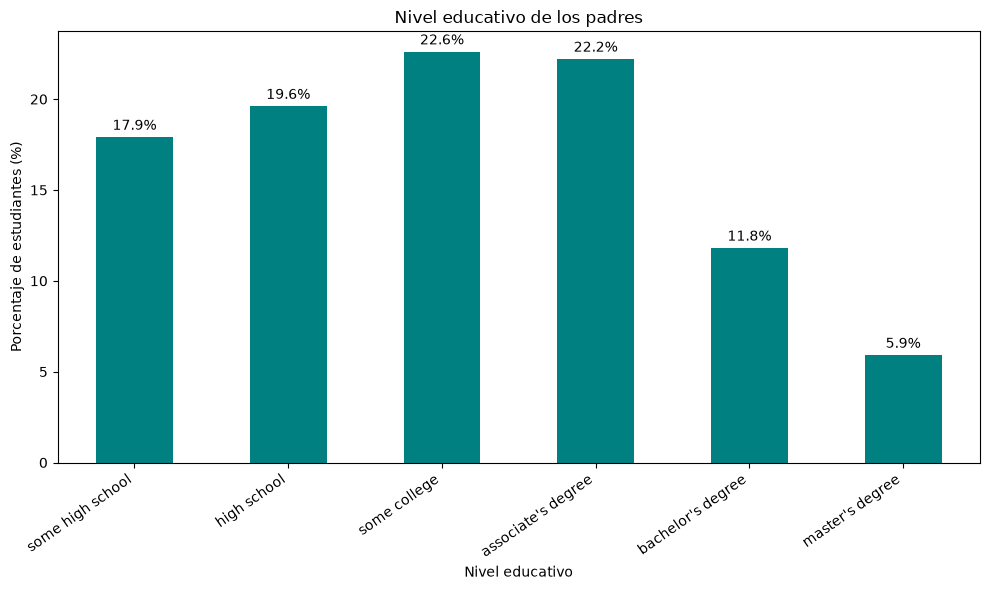

In [3]:
orden = ["some high school", "high school", "some college", "associate's degree", "bachelor's degree", "master's degree"]

porcentajes = sp["parental_level_of_education"].value_counts(normalize=True).reindex(orden) * 100

datos = porcentajes.plot(kind="bar", figsize=(10, 6), color="teal")

datos.bar_label(datos.containers[0], fmt="%.1f%%", padding=3)

plt.title("Nivel educativo de los padres")
plt.ylabel("Porcentaje de estudiantes (%)")
plt.xlabel("Nivel educativo")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig("../img/Grafico_4_1.jpg", dpi=300, bbox_inches="tight")

plt.show()

Observamos que el 39.9% tienen un titulo superior, un grado universitario o un máster. Por lo que más de la mitad de la muestra tienen niveles inferiores.

* Ahora vamos a ver el rendimiento académico medio según el nivel educativo de los padres:

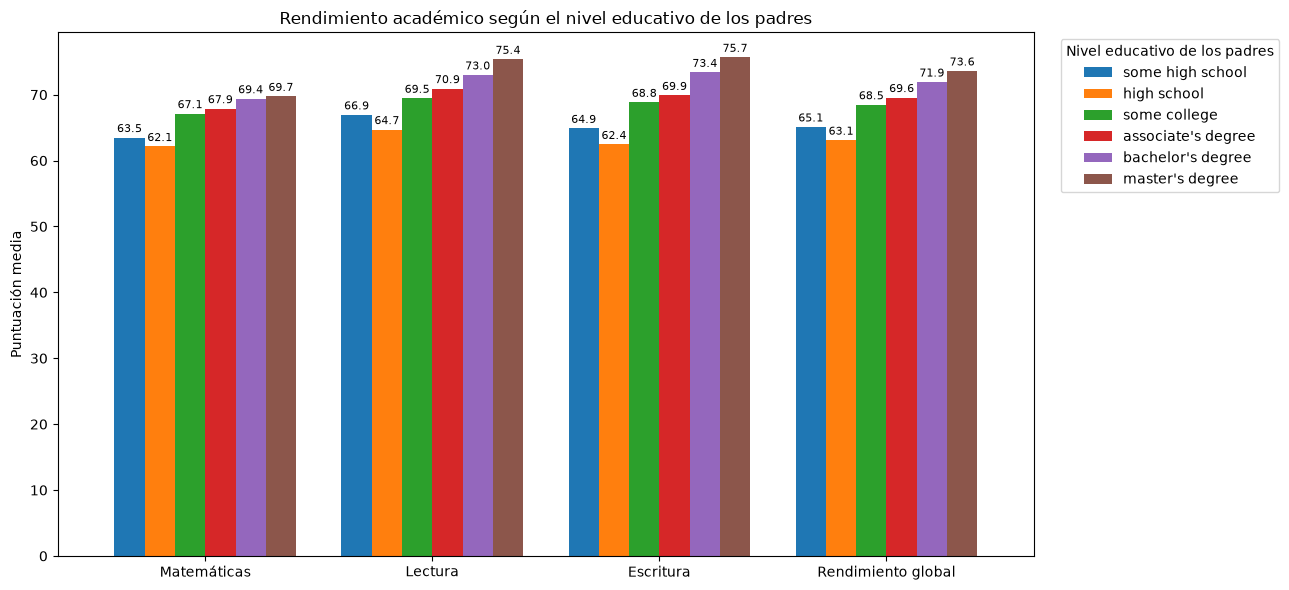

In [4]:
rendimiento_padres = sp.groupby("parental_level_of_education")[["math_score", "reading_score", "writing_score", "global_score"]].mean()

rendimiento_padres = rendimiento_padres.reindex(orden)

rendimiento_padres = rendimiento_padres.T

ren = rendimiento_padres.plot(kind="bar", figsize=(13, 6), width=0.8)

for barras in ren.containers:
    ren.bar_label(barras, fmt="%.1f", padding=2, fontsize=8)

ren.set_title("Rendimiento académico según el nivel educativo de los padres")
ren.set_ylabel("Puntuación media")
ren.set_xticklabels(["Matemáticas", "Lectura", "Escritura", "Rendimiento global"], rotation=0)
ren.legend(title="Nivel educativo de los padres", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()

plt.savefig("../img/Grafico_4_2.jpg", dpi=300, bbox_inches="tight")

plt.show()

En todas las competencias parece que existe la evidencia de que a mayor nivel de estudios parental, se consiguen mejores resultados en los exámenes. 

Las diferencias se hacen más visibles en "Lectura" y "Escritura".

* Vamos a ver la distribución del rendimiento global según el nivel educativo de los padres:

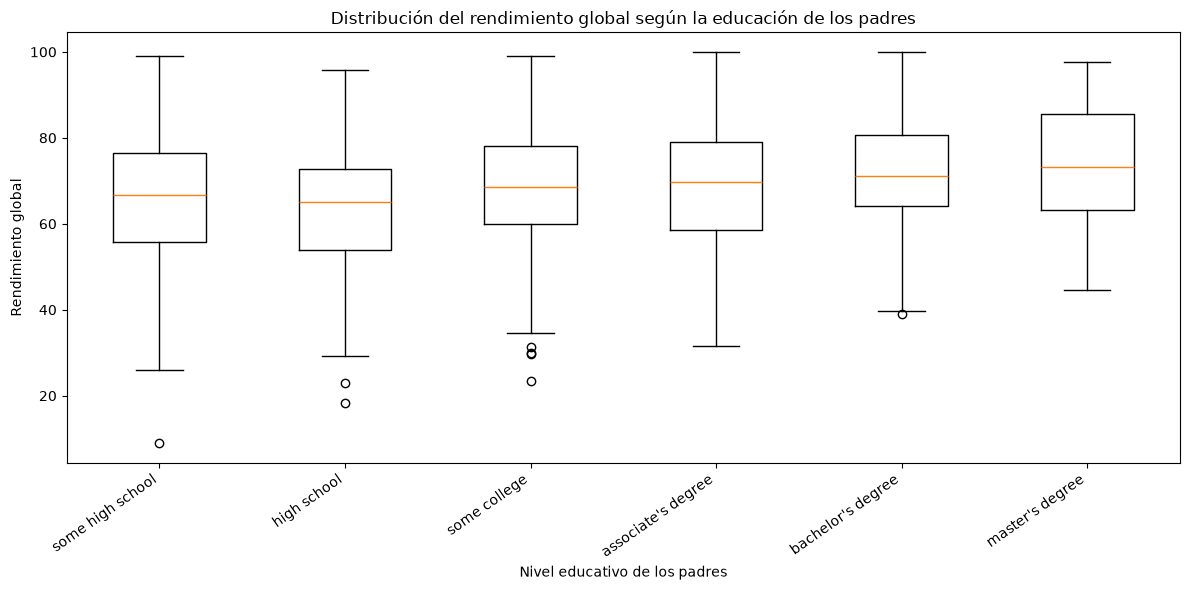

In [5]:
orden = ["some high school", "high school", "some college", "associate's degree", "bachelor's degree", "master's degree"]

dat = [sp.loc[sp["parental_level_of_education"] == nivel, "global_score"].dropna() for nivel in orden]

plt.figure(figsize=(12, 6))

plt.boxplot(dat, tick_labels=orden)

plt.title("Distribución del rendimiento global según la educación de los padres")
plt.xlabel("Nivel educativo de los padres")
plt.ylabel("Rendimiento global")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()

plt.savefig("../img/Grafico_4_3.jpg", dpi=300, bbox_inches="tight")

plt.show()


Confirma los resultados anteriores: la mediana y los cuartiles son mayores a mayor grado educativo de los padres.
Por lo que puedemos hablar de una asociación entre ambas variables.

El siguiente paso sería realizar un contraste estadístico entre los seis niveles educativos para comprobar si las diferencias de rendimiento que aparecen en los gráficos son significativas. Para eso utilizaríamos un ANOVA de un factor.